# Projeto 01 — Pesquisa Local (Hill-Climbing)
## IA26_P01_G04 — Gonçalo Correia (22840), Bruno Dantas (27958), Ricardo Ferreira (25426)

Notebook de pesquisa local: Hill-Climbing sobre a solução do Greedy. Executar com a raiz do repositório como diretório de trabalho (necessita de `data/`, `model.py`, `informed.py` e `local_search.py`).

In [1]:
import os
import sys

# Os notebooks vivem em notebooks/; passa para a raiz do projeto para que
# os caminhos "data_tiny" e "src" funcionem, quer se execute a partir da raiz, quer de notebooks/.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

### 4.2 Parte B — Pesquisa local (Hill-Climbing)

O objetivo é melhorar uma solução inicial por exploração iterativa de rotas vizinhas. A solução inicial vem do **Greedy Best-First** (`informed.py`), que é rápido mas não garante a rota mais curta; o Hill-Climbing parte dela e tenta reduzir a distância total. O código está em `local_search.py`.

#### 4.2.1 Cenário e formulação

Usámos os artigos **7, 10, 17 e 22**, com partida em **19/10/2026 às 07:30** do depósito **6**. Com apenas os artigos 7 e 10 o Greedy já devolve a rota ótima, pelo que não haveria nada a melhorar; com quatro artigos há margem para a pesquisa local.

* **Solução:** rota completa `[("start", 6), ..., ("regresso", 6)]`, com as recolhas e entregas dos quatro artigos.
* **Custo:** distância total em km (critério de desempate: duração em minutos). Uma rota inviável tem custo infinito.
* **Vizinhança:** movimentos *relocate* (mover um passo para outra posição) e *swap* (trocar dois passos). A partida e o regresso ao depósito mantêm-se fixos. Cada vizinho é validado por `route_feasibility_checker()` e avaliado por `cost_function()`, pelo que a precedência, a capacidade e as janelas temporais são sempre respeitadas.
* **Algoritmo:** Hill-Climbing de melhor vizinho (*steepest ascent*). Em cada iteração avalia toda a vizinhança e move-se para o melhor vizinho, se este for estritamente melhor. Pára no primeiro ótimo local.

In [2]:
import random
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from model import Problem
from informed import greedy_best_first, heuristic, reconstruct_route
from local_search import hill_climbing, random_restart_hill_climbing

items_b = [7, 10, 17, 22]
start_time_b = pd.Timestamp("2026-10-19 07:30:00")

problem_b = Problem(data_folder="data_tiny")
problem_b.requests = [r for r in problem_b.requests if r.item_id in items_b]
problem_b.requests_by_id = {r.item_id: r for r in problem_b.requests}

# Resumo dos artigos do cenário
display(pd.DataFrame([{
    "Artigo": r.item_id, "Peso (kg)": round(r.weight_kg, 2),
    "Recolha (local)": r.pickup_location_id, "Entrega (local)": r.delivery_location_id,
    "Janela de recolha": f"{r.availability_start:%d/%m %H:%M}–{r.availability_end:%H:%M}",
    "Janela de entrega": f"{r.delivery_start:%d/%m %H:%M}–{r.delivery_end:%H:%M}",
} for r in problem_b.requests]))

,Artigo,Peso (kg),Recolha (local),Entrega (local),Janela de recolha,Janela de entrega
0,7,21.10,4,10,19/10 08:30–13:30,19/10 11:30–12:30
1,10,6.54,4,8,19/10 07:30–09:30,19/10 08:30–12:30
2,17,10.40,1,9,19/10 10:00–16:00,20/10 13:00–15:00
3,22,2.64,4,8,19/10 12:15–15:15,19/10 16:15–18:15


#### 4.2.2 Execução: Greedy → Hill-Climbing

Para cada veículo, o Greedy (heurística `heuristic`) gera a rota inicial e o Hill-Climbing melhora-a. O tempo do Hill-Climbing mede apenas a pesquisa; a rota final é confirmada pelo validador.

In [3]:
results_b = []
histories_b = {}
for vehicle_id in (1, 2):
    depot = problem_b.vehicles[vehicle_id].center_location_id
    goal, _ = greedy_best_first(problem_b, vehicle_id, start_time_b, heuristic)
    initial_route = reconstruct_route(goal, depot)

    result = hill_climbing(problem_b, initial_route, vehicle_id, start_time_b)

    # Confirmação da rota final com o validador
    feasible, reason, _ = problem_b.route_feasibility_checker(
        result["route"], vehicle_id, start_time_b)
    assert feasible, reason

    histories_b[vehicle_id] = result["history"]
    results_b.append({
        "Veículo": vehicle_id,
        "Greedy (km)": result["history"][0],
        "Hill-Climbing (km)": result["distance_km"],
        "Melhoria (km)": result["history"][0] - result["distance_km"],
        "Duração (min)": result["duration_min"],
        "Iterações": result["iterations"],
        "Vizinhos avaliados": result["evaluated"],
        "Tempo (ms)": result["time_ms"],
        "Viável": feasible,
    })
    print(f"Veículo {vehicle_id} — rota final:")
    for step in result["route"]:
        print("   ", step)

display(pd.DataFrame(results_b).round(2))

Veículo 1 — rota final:
    ('start', 6)
    ('recolha', 7)
    ('recolha', 10)
    ('entrega', 10)
    ('recolha', 17)
    ('entrega', 7)
    ('recolha', 22)
    ('entrega', 22)
    ('entrega', 17)
    ('regresso', 6)
Veículo 2 — rota final:
    ('start', 6)
    ('recolha', 7)
    ('recolha', 10)
    ('entrega', 10)
    ('recolha', 17)
    ('entrega', 7)
    ('recolha', 22)
    ('entrega', 22)
    ('entrega', 17)
    ('regresso', 6)


,Veículo,Greedy (km),Hill-Climbing (km),Melhoria (km),Duração (min),Iterações,Vizinhos avaliados,Tempo (ms),Viável
0,1,343.91,304.69,39.22,1802.2,2,210,23.36,True
1,2,343.91,304.69,39.22,1802.2,2,210,28.03,True


#### 4.2.3 Curva de custo por iteração

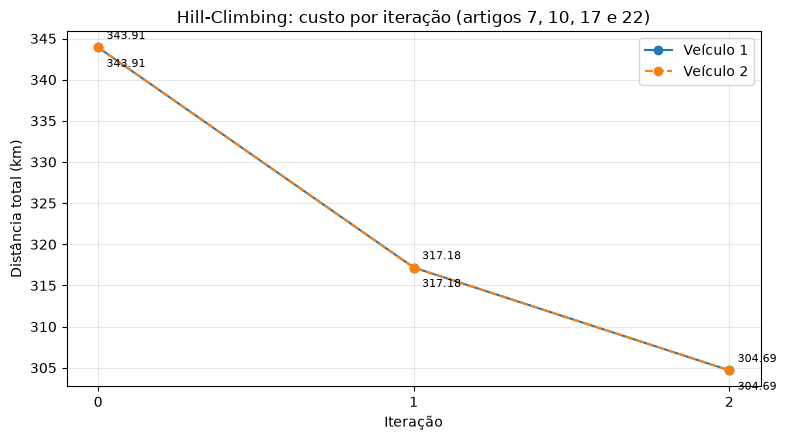

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for vehicle_id, history in histories_b.items():
    ax.plot(range(len(history)), history, marker="o", linestyle="--" if vehicle_id == 2 else "-",
            label=f"Veículo {vehicle_id}")
    for it, cost in enumerate(history):
        ax.annotate(f"{cost:.2f}", (it, cost), textcoords="offset points",
                    xytext=(6, 6 if vehicle_id == 1 else -14), fontsize=8)
ax.set_xlabel("Iteração")
ax.set_ylabel("Distância total (km)")
ax.set_title("Hill-Climbing: custo por iteração (artigos 7, 10, 17 e 22)")
ax.set_xticks(range(max(len(h) for h in histories_b.values())))
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

#### 4.2.4 Reinícios aleatórios (verificação do ótimo local)

O Hill-Climbing simples pára no primeiro ótimo local, que pode não ser o melhor. Para o testar, repetimos a pesquisa a partir de 10 rotas viáveis aleatórias (semente fixa) e guardamos a melhor.

In [5]:
rr = random_restart_hill_climbing(problem_b, items_b, 1, start_time_b, restarts=10, seed=42)
print(f"Reinícios aleatórios (10): melhor distância = {rr['distance_km']:.2f} km, "
      f"duração = {rr['duration_min']:.2f} min, tempo total = {rr['time_ms']:.1f} ms")

Reinícios aleatórios (10): melhor distância = 304.69 km, duração = 1802.20 min, tempo total = 911.4 ms


#### 4.2.5 Análise crítica

**Qualidade da solução.** O Greedy devolve uma rota de **343,91 km**; o Hill-Climbing reduz-a para **304,69 km** (−39,22 km, cerca de 11%) em apenas 2 iterações. É uma solução válida melhor do que a inicial. A demonstração não compara exaustivamente as rotas nem executa A* neste cenário de quatro artigos, pelo que não permite afirmar que seja o ótimo global.

**Comportamento.** A melhoria vem de reordenar recolhas e entregas: em vez de entregar tudo no fim, o Hill-Climbing intercala passos de forma a reduzir deslocações, sem violar as janelas temporais (cada vizinho inviável tem custo infinito e nunca é escolhido). As curvas dos dois veículos são iguais porque partem do mesmo depósito, usam a mesma matriz de distâncias e as capacidades são muito superiores à carga transportada.

**Duração.** A duração (1802 min) é elevada porque inclui a espera pela janela de entrega do artigo 17, que só abre a 20/10 às 13:00; a otimização é feita sobre a distância, não sobre a duração.

**Limitações.** O Hill-Climbing só aceita melhorias estritas, por isso pode ficar preso num ótimo local ou num planalto; a qualidade depende da solução inicial e da vizinhança. Os reinícios aleatórios reduzem esse risco, e aqui convergiram para o mesmo valor, sem demonstrar optimalidade global. Com poucos artigos, a vizinhança é pequena (cerca de 70 vizinhos por iteração); com mais artigos cresce quadraticamente e o custo de avaliação aumentaria.

**Custo computacional.** Os tempos são de uma única execução e dependem do ambiente, pelo que não sustentam conclusões sobre desempenho relativo. Fica como melhoria futura medir em vários cenários maiores e testar vizinhanças adicionais (por exemplo, mover pares recolha–entrega) ou simulated annealing.